# Exploratory Data Analysis
#### This notebook is used to open files and understand file structure
- Counts the number of image files in each folder (in both Test and Training)
- Avoids unnecessary analysis in the Test dataset to prevent data leakage risks
- Also explores image structure, pixel size/consistency
- Acts as a cleaning file as well by adjusting all image sizes to be consistent
- At the end, a few images from each set of cancer cells will be shown in a grid along with some descriptions made by human observation
- It is also highly advised to go through several Training set images prior to EDA for a more intuitive grasp

### Importing the appropriate libraries/modules

In [1]:
#Import statements

import os
from pathlib import Path
from collections import defaultdict
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import random


#path to root directory
#'user/folder_to_data'
ROOT_DIR = Path('/Users/anjalisrinivasan/Desktop/projects/cervical_cell_classifier/data')

### Understanding how our dataset files look like & are structured

In [2]:
#checking the file structure
#shows what folders are inside of the data folder
#should be two folders split into Testing and Training
#within each, there should be a Superficial-Intermediate, Parabasal, Koilocytotic, Metaplastic, Dyskeratotic
for path in ROOT_DIR.rglob("*"):
    if path.is_dir():
        print(path)

/Users/anjalisrinivasan/Desktop/projects/cervical_cell_classifier/data/Test
/Users/anjalisrinivasan/Desktop/projects/cervical_cell_classifier/data/Training
/Users/anjalisrinivasan/Desktop/projects/cervical_cell_classifier/data/Test/im_Metaplastic
/Users/anjalisrinivasan/Desktop/projects/cervical_cell_classifier/data/Test/im_Dyskeratotic
/Users/anjalisrinivasan/Desktop/projects/cervical_cell_classifier/data/Test/im_Superficial-Intermediate
/Users/anjalisrinivasan/Desktop/projects/cervical_cell_classifier/data/Test/im_Parabasal
/Users/anjalisrinivasan/Desktop/projects/cervical_cell_classifier/data/Test/im_Koilocytotic
/Users/anjalisrinivasan/Desktop/projects/cervical_cell_classifier/data/Training/im_Metaplastic
/Users/anjalisrinivasan/Desktop/projects/cervical_cell_classifier/data/Training/im_Dyskeratotic
/Users/anjalisrinivasan/Desktop/projects/cervical_cell_classifier/data/Training/im_Superficial-Intermediate
/Users/anjalisrinivasan/Desktop/projects/cervical_cell_classifier/data/Traini

### Checks how many images are in each cell type folder in both Training & Test
- Done to see if the number of images is wildy inconsistent within the different folders or similar

In [21]:
#Count the number of images per split 
#First in training set and then test set for each cell type category
#the valid image extensions -> most of this dataset is already in bmp format, which is lossless quality
valid_ext = {'.bmp','.jpg','.jpeg','.png'}
def count_split_images(ROOT_DIR, split, valid_ext):
    data_dir = ROOT_DIR / split
    counts = defaultdict(int)
    #searches in all the files and folders within this path -> gives total number of images in the entire training set
    for path in data_dir.rglob("*"):
        #makes sure the path is actually a file and checks if the extension is valid based off the list we gave it
        #also converts the image extension into all lowercase incase of any differences 
        if path.is_file() and path.suffix.lower() in valid_ext:
            #cuts off common prefix so will create tuples for all the files assuming /Training is the root dir instead
            #will look like: /Parabasal/img
            inner_file_path = path.relative_to(data_dir).parts
            #key groups the files by subgroup -> cell type, by cutting off the name of the image from the tuple 
            key = inner_file_path[:-1]
            #creates a key item and increments it by 1 each time the same key is encountered when splitting into tuples
            counts[key] += 1
    return counts

#counts the num of images in the training set
train_counts = count_split_images(ROOT_DIR, 'Training', valid_ext)
print("TRAINING COUNTS:")
print(train_counts)
#counts the num of images in the test set
test_counts = count_split_images(ROOT_DIR, 'Test', valid_ext)
print("TEST COUNTS:")
print(test_counts)

TRAINING COUNTS:
defaultdict(<class 'int'>, {('im_Metaplastic',): 693, ('im_Dyskeratotic',): 713, ('im_Dyskeratotic', '.ipynb_checkpoints'): 1, ('im_Superficial-Intermediate',): 731, ('im_Parabasal',): 687, ('im_Koilocytotic',): 725})
TEST COUNTS:
defaultdict(<class 'int'>, {('im_Metaplastic',): 100, ('im_Dyskeratotic',): 100, ('im_Superficial-Intermediate',): 100, ('im_Parabasal',): 100, ('im_Koilocytotic',): 100})


### Checking to see if any files in the folders do not have a valid extension

In [ ]:
# corruption test to see if any of the files are not in the correct file format
# should only return .DS_Store

valid_ext = {'.bmp','.jpg','.jpeg','.png'}
def count_invalid_images(ROOT_DIR, split, valid_ext):
    data_dir = ROOT_DIR / split
    counts = defaultdict(int)
    for path in data_dir.rglob("*"):
        #checks if there are files without the valid file extensions
        if path.is_file() and path.suffix.lower() not in valid_ext:
            inner_file_path = path.relative_to(data_dir).parts
            key = inner_file_path[:-1]
            counts[key] += 1
            print(path)
    return counts

print(count_invalid_images(ROOT_DIR, 'Training', valid_ext))

/Users/anjalisrinivasan/Desktop/projects/cervical_cell_classifier/data/Training/.DS_Store
defaultdict(<class 'int'>, {(): 1})


### Physically plotting bar charts to visualize counts for cell types

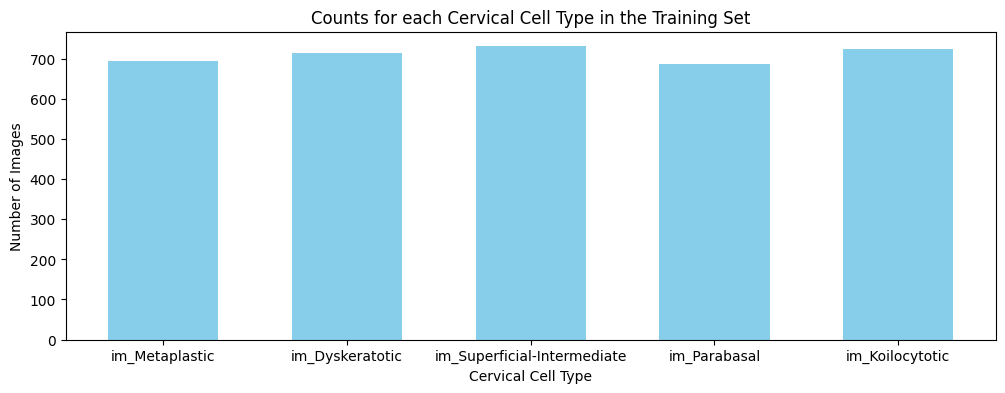

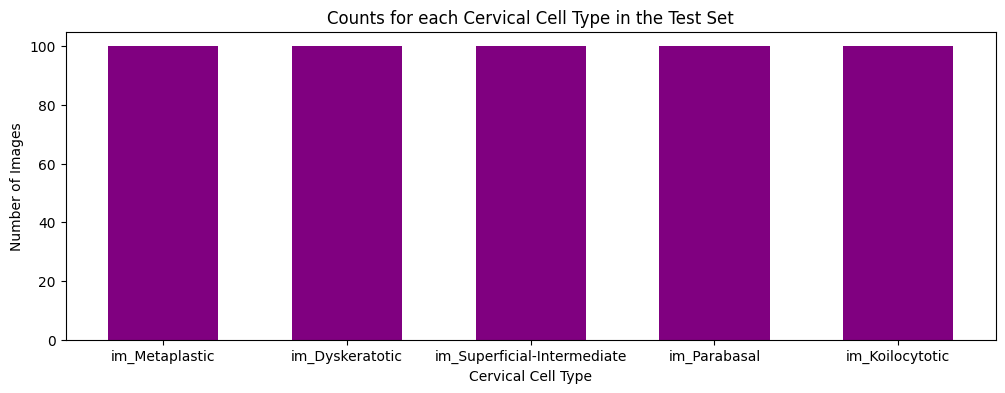

In [23]:
# to ensure that the training counts and test counts are balanced, use visual bar plots
# if each category within training is roughly equal, this will make sure the model does not have bias towards one category
# the test counts in the SPIKAMED dataset are all 100 images per category so they are already unbiased and equal, but printed the bar plot anyway

#can change based on varying categories and values
split_categories = ['im_Metaplastic', 'im_Dyskeratotic', 'im_Superficial-Intermediate', 'im_Parabasal', 'im_Koilocytotic']
train_values = [693, 713, 731, 687, 725]
test_values = [100, 100, 100, 100, 100]

plt.figure(figsize=(12, 4))
plt.bar(split_categories, train_values, color = 'skyblue', width = 0.6)
plt.title('Counts for each Cervical Cell Type in the Training Set')
plt.xlabel('Cervical Cell Type')
plt.ylabel('Number of Images')

plt.show()

plt.figure(figsize=(12, 4))
plt.bar(split_categories, test_values, color = 'purple', width = 0.6)
plt.title('Counts for each Cervical Cell Type in the Test Set')
plt.xlabel('Cervical Cell Type')
plt.ylabel('Number of Images')

plt.show()

###RESULT FROM SPIKAMED DATASET: The training data was roughly equal to each other with the least images for Parabasal and 
###the most images from superficial-intermediate. The test data set was created equalyl with 100 images in each category already
###both can be used as shown


### Checks pixel height and width for all images to ensure consistency
- Cannot move on to training images on ML models if they are all different sized images

In [24]:
# define image properties + check for inconsistencies
# check image size an ensure each image has the exact same sizing, otherwise they must be changed/discarded
# use a smaller sample of the images to generally check - not every image needs to be checked
def check_image_size(ROOT_DIR, split, valid_ext, sample_size):
    data_dir = ROOT_DIR / split
    #path number in the series of images in the folde3r
    path_num = 0
    #list of first sample_size number images
    image_subset = []
    for path in data_dir.rglob("*"):
        if path.suffix.lower() in valid_ext:
            path_num+=1
            image_subset.append(path)
            if(path_num == sample_size):
                break

    #creates list of the sizes, modes, and formats of the sample_size number images
    #pixel size height and width
    img_sizes = []
    #RGB, grayscale, etc
    img_modes = []
    for path in image_subset:
        with Image.open(path) as img:
            img_sizes.append(img.size)
            img_modes.append(img.mode)

    #print findings
    widths, heights = zip(*img_sizes)
    print(split)
    print(f"Max image width: {max(widths)} \n Min image width: {min(widths)}")
    print(f"Max image height: {max(heights)} \n Min image width: {min(heights)}")
    print(f"Median image (H, W):( {np.median(heights)} , {np.median(widths)} )")
    print(f"All unique widths recorded: {set(widths)}")
    print(f"All unique heights recorded: {set(heights)}")
    print(f"All unique image modes recorded: {set(img_modes)}")
                

check_image_size(ROOT_DIR, 'Training', valid_ext, 500)
check_image_size(ROOT_DIR, 'Test', valid_ext, 500)

Training
Max image width: 503 
 Min image width: 97
Max image height: 347 
 Min image width: 91
Median image (H, W):( 173.0 , 193.0 )
All unique widths recorded: {97, 102, 103, 104, 105, 106, 109, 110, 114, 116, 118, 119, 120, 121, 122, 123, 124, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 224, 225, 226, 227, 228, 229, 230, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 249, 250, 251, 252, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 266, 267, 268, 269, 270, 271, 272, 273, 275, 276, 278, 280, 284, 286, 287, 288, 289, 290, 291, 294

### Resizing image function to change all images to a consistne pixel measurement

In [35]:
# image resizing code to help crop all images to a certain size
# same size needs to be used in ML models for consistency and to avoid size mismatch errors
# in the SPIKAMED dataset used, the images in both training and test came in a WIDE variety of sizes

input_dir = Path('/Users/anjalisrinivasan/Desktop/projects/cervical_cell_classifier/data')
output_dir = Path('/Users/anjalisrinivasan/Desktop/projects/cervical_cell_classifier/data_new')
def resize_images(input_dir, output_dir, split, valid_ext, size):
    data_dir = input_dir / split
    for path in data_dir.rglob("*"):
        if path.suffix.lower() not in valid_ext:
            if path.suffix.lower() == '':
                print(f"Invalid extension: null ext: {path.name}")
            else:
                print(f"Invalid extension: {path.suffix}")
            continue
        
        try:
            # open and resize the image
            img = Image.open(path).resize(size)
            # exact destination path name
            save_path = output_dir / split / path.relative_to(data_dir)
            # checks to see if the cell type folder exists; creates one if it does not
            save_path.parent.mkdir(parents=True, exist_ok=True)
            # saves the resized image to the destination path
            img.save(save_path)
        except Exception as e:
            print(f"Failed to process {path}: {e}")

# chose to do a size of 160 by 160 based off the Training data median (173, 193)
# only made a choice based off of Training data because using Test data would create a data leakage as it would influence my decision
# chose to do 170 x 170 because it is the decision that is most losless (retains the most data) 
resize_images(input_dir, output_dir, 'Training', valid_ext, (170,170))
resize_images(input_dir, output_dir, 'Test', valid_ext, (170,170))

Invalid extension: null ext: .DS_Store
Invalid extension: null ext: im_Metaplastic
Invalid extension: null ext: im_Dyskeratotic
Invalid extension: null ext: im_Superficial-Intermediate
Invalid extension: null ext: im_Parabasal
Invalid extension: null ext: im_Koilocytotic
Invalid extension: null ext: .ipynb_checkpoints
Invalid extension: null ext: .DS_Store
Invalid extension: null ext: im_Metaplastic
Invalid extension: null ext: im_Dyskeratotic
Invalid extension: null ext: im_Superficial-Intermediate
Invalid extension: null ext: im_Parabasal
Invalid extension: null ext: im_Koilocytotic


### Double check to ensure all images are in the newly corrected pixel format

In [36]:
# check to make sure the new data is now all in the correct format
# this should be done only AFTER reszing the images
# simplified version of check_image_size
def check_new_images(output_dir, split, valid_ext, sample_size, img_size):
    data_dir = output_dir / split
    path_num = 0
    new_image_subset = []
    for path in data_dir.rglob("*"):
        if path.suffix.lower() in valid_ext:
            path_num+=1
            new_image_subset.append(path)
            if(path_num == sample_size):
                break

    new_img_sizes = []
    for path in new_image_subset:
        with Image.open(path) as img:
            new_img_sizes.append(img.size)

    #print findings; should have a unique set of just 1 number per width and height (equal to img_size)
    widths, heights = zip(*new_img_sizes)
    print(split)
    print(f"All unique widths recorded: {set(widths)}")
    print(f"All unique heights recorded: {set(heights)}")
    if(len(set(widths)) == 1 and len(set(heights)) == 1):
        # if we know that the sets are uniquely 1 value, now check if that value is what we intended 
        # define the real w and h by popping that value from the set
        actual_width = set(widths).pop()
        actual_height = set(heights).pop()
        if actual_width == img_size[0] and actual_height == img_size[1]:
            print("Successfully converted all images into one size!")
        else:
            print("Warning: Inconsistent file sizes found.")
                

check_new_images(output_dir, 'Training', valid_ext, 200, (170,170))
check_new_images(output_dir, 'Test', valid_ext, 200, (170,170))

Training
All unique widths recorded: {170}
All unique heights recorded: {170}
Successfully converted all images into one size!
Test
All unique widths recorded: {170}
All unique heights recorded: {170}
Successfully converted all images into one size!


### Print out a grid of images from each cell type folder to allow user to visualize example cells

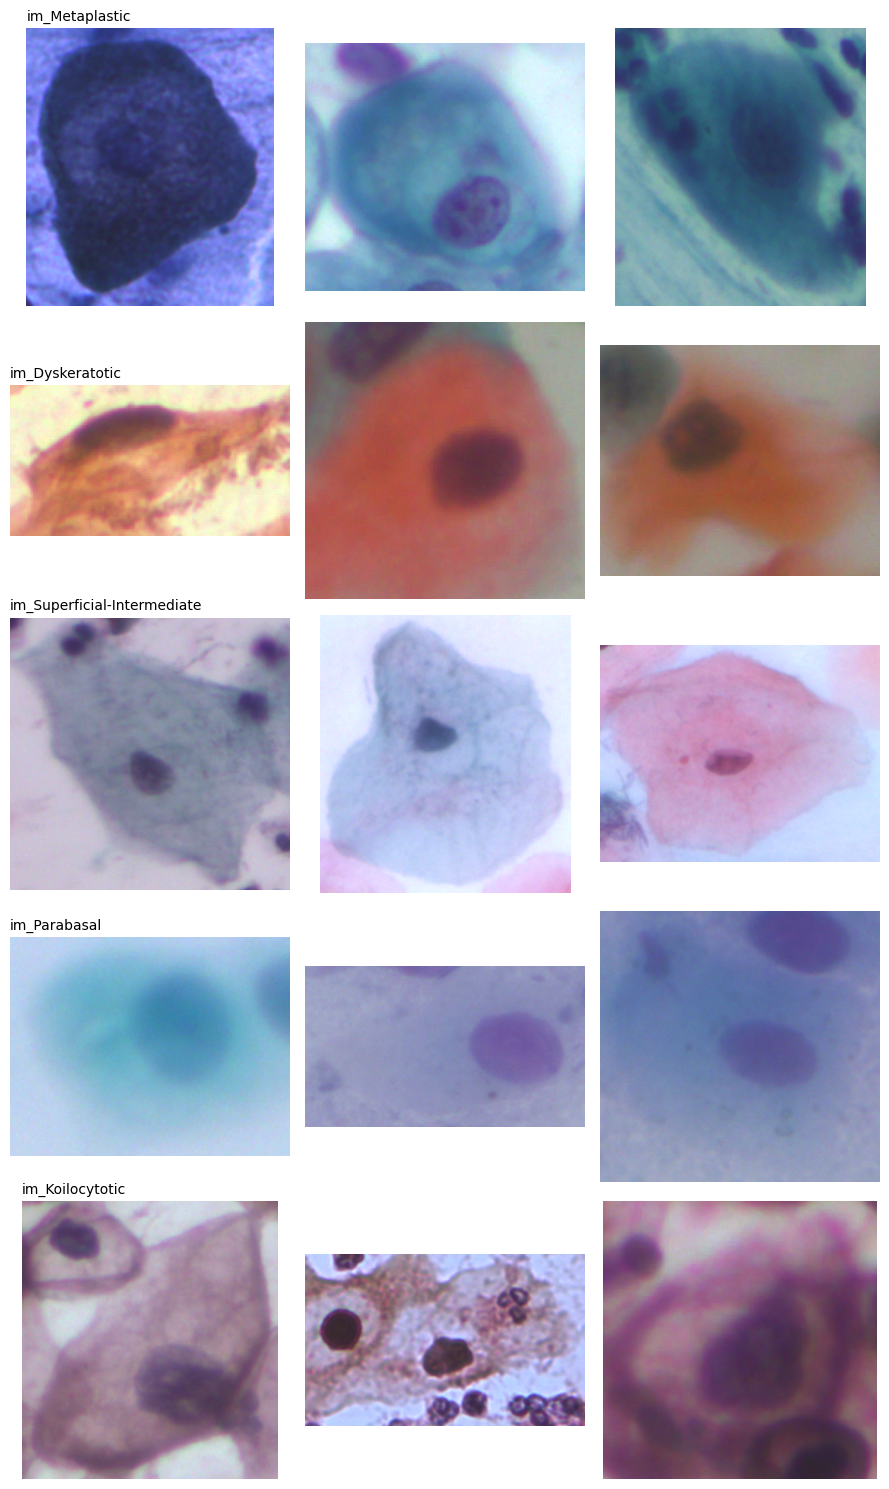

In [42]:
# actually viewing the images and identifying the characteristics of each category of cervical cancer cell type
# shows 3 images per category along with some comments for user observations
# from the SPIKAMED dataset on Kaggle

def show_sample_grid(data_dir, split, valid_ext, img_per_class=3):
    # get all class folders (e.g. Parabasal, Koilocytotic, etc.)
    class_dirs = [d for d in (data_dir / split).iterdir() if d.is_dir()]
    
    # set up a grid: one row per class, n_per_class columns
    fig, axes = plt.subplots(len(class_dirs), img_per_class, 
                              figsize=(img_per_class * 3, len(class_dirs) * 3))
    
    for row, class_dir in enumerate(class_dirs):
        # grab valid images from this class folder
        images = [p for p in class_dir.iterdir() if p.suffix.lower() in valid_ext]
        sample = random.sample(images, min(img_per_class, len(images)))
        
        for col, img_path in enumerate(sample):
            img = Image.open(img_path)
            ax = axes[row, col]
            ax.imshow(img)
            ax.axis('off')
        
        # label the row with the class name, on the first column only
        axes[row, 0].set_title(class_dir.name, loc='left', fontsize=10)
    
    plt.tight_layout()
    plt.show()

# can change to be either the input_dir or output_dir to see both the original and modified images
# input_dir can be more useful for human user to identify differences between cell types
# can change img_per_class to see more images per cell type
show_sample_grid(input_dir, 'Training', valid_ext, img_per_class=3)

### Human User Analysis/Generalizations Based on Sample Images
#### Below are a few generalizations for each cancer cell type based on how they appear to a human user
##### Metaplastic: 
- Benign cells (currently not harmful) but are in the watch zone for malignant behavior
- Shape: Round-ish or oval-ish with a pretty visible, thick appearing membrane border
- Nucleus: Appears round and normal appearing
##### Dyskeratotic: 
- Abnormal cells that are malignant
- Shape: All sorts of shapes (stretched out, slightly circular, square shaped, etc)
- Cytoplasm: Appears hardened or thick throughout with no clear separation of membrane, pink/orange color
##### Superficial-Intermediate:
- Normal, mature cells
- Shape: Not fully circular; appears to cover as much space as possible and take up any shape
- Nucleus: Very small, normal appearing; small nucleus to cytoplasm ratio
- Cytoplasm: Very flat, thin/clear appearing
##### Parabasal:
- Normal, less mature cells (comes before Superficial-Intermediate)
- Shape: Appears in a circle/oval shape, smaller than Superficial-Int
- Nucleus: Larger nucleus to cytoplasm ratio, clean oval shape
- Cytoplasm: Thin cytoplasm with no clear separation of membrane
##### Koliocytotic:
- Abnormal cell that are malignant, HPV associated
- Shape: Wide, irregular shape, closely next to its neighboring cells
- Nucleus: Large nucleus compared to cytoplasm
- Cytoplasm: Thinner, veiny appearing cytoplasm with very thick, halo-looking membrane

# EDA Notebook Conclusion Write up
##### Some conclusions found based off this exploratory data using the SPIKAMED dataset
- All images are in RBG
- All images came in varous sizes, and have now been resized to (170,170) height x width
- New reszed data have been saved into "data_new" file
- Training set data have more images than Test data; each folder in Test data have 100 images
- The folders in the Training set are close enough to each other to use